Today's topics:
* comparing fitted forms with one `rmse(y, y_fit)` score
* normalizing a measured curve before fitting
* fitting a transition midpoint by minimizing a sum of squared residuals

# Two fitting examples from superconducting films

Today we will work through two complete questions using FeSe-film resistance
measurements. First we will choose a model for the smooth change *above* the
superconducting transition. Then we will describe the sharp transition itself.

*Which form describes the normal-state resistance? At what temperature does
this film pass through the middle of its superconducting transition?*

These measurements are from Penn State's 2D Crystal Consortium
([data package](https://doi.org/10.26207/j3vb-gg87), CC BY 4.0).
The table contains four FeSe films. We will start with film 20198; the
second film in the check for understanding uses the same steps with its own
fitting window and starting values. Resistance is in ohms ($\Omega$).

> Below its transition, a superconductor has nearly zero resistance.
> A few readings just below zero in this table are instrument noise around zero.

We saw a FeSe transition as a picture in Lecture 11. Today we fit the numbers.

<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"
  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">


# Example 1: a normal-state model

**Question:** Which familiar form gives a useful summary of the resistance
above the transition, and where may we report that fit?

Start with all the readings for film 20198. Look at the full curve and then
zoom in on the part where resistance rises sharply:

Text(0, 0.5, 'resistance ($\\Omega$)')

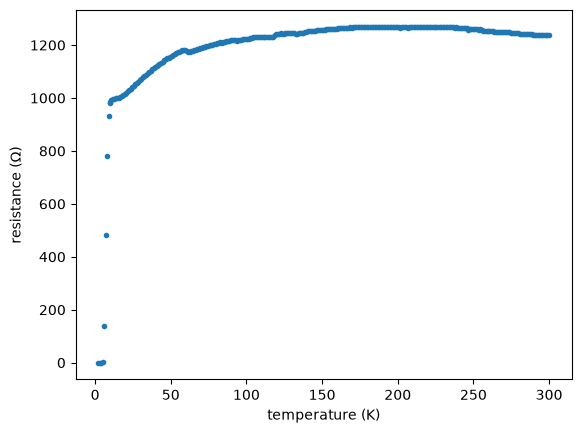

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/staging/datasets/fese_transport_2dcc.csv')
film = data.loc[data['sample_id'] == 20198]

fig, ax = plt.subplots()
ax.plot(film['temperature_K'], film['resistance_ohm'], '.')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance ($\\Omega$)')

Text(0, 0.5, 'resistance ($\\Omega$)')

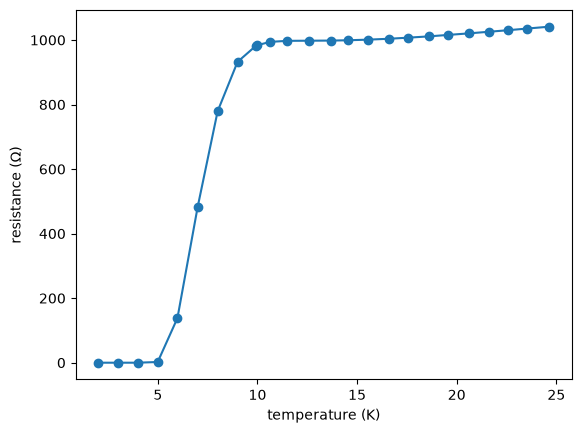

In [2]:
low_temperature = film.loc[film['temperature_K'] <= 25]
fig, ax = plt.subplots()
ax.plot(low_temperature['temperature_K'], low_temperature['resistance_ohm'], 'o-')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance ($\\Omega$)')

Near 2 K the resistance is almost zero; near 11 K it is about
1000 $\Omega$.

For this first question, keep only readings at 20 K and above.
Before fitting, predict whether a straight line or a curved form will leave
smaller misses over this range.

In [3]:
normal = film.loc[film['temperature_K'] >= 20]
temperature = normal['temperature_K'].to_numpy()
resistance = normal['resistance_ohm'].to_numpy()
print(len(normal), 'normal-state readings')

280 normal-state readings


## A shared score

Use the same RMSE calculation for every form. The score has the units of
the resistance, so a smaller number means a smaller typical miss in ohms:

In [4]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    residuals = y - y_fit  # measured minus predicted
    return np.sqrt(np.mean(residuals**2))

## Fit three familiar forms

Start with a line as the simplest reference:

In [5]:
line = stats.linregress(temperature, resistance)
resistance_line = line.slope * temperature + line.intercept
print(f'line: RMSE = {rmse(resistance, resistance_line):.1f} ohm')

line: RMSE = 37.6 ohm


A quadratic can bend. `curve_fit` finds its three constants:

In [6]:
def quadratic(T, a, b, c):
    """Resistance in ohm from a*T**2 + b*T + c; T is in K."""
    return a * T**2 + b * T + c

popt_quad, pcov_quad = optimize.curve_fit(quadratic, temperature, resistance)
resistance_quad = quadratic(temperature, *popt_quad)
print(f'quadratic: RMSE = {rmse(resistance, resistance_quad):.1f} ohm')

quadratic: RMSE = 13.3 ohm


The curve rises quickly and then levels off over this range. Try a
saturating exponential: $R(T)=A(1-e^{-kT})+R_0$. This is a descriptive
fitting form for these readings, not a theory of superconductivity.

In [7]:
def saturation_model(T, A, k, R0):
    """Resistance in ohm from A*(1 - exp(-k*T)) + R0; T is in K."""
    return A * (1 - np.exp(-k * T)) + R0

## Can you beat `curve_fit`?

Move $A$, $k$, and $R_0$ to lower the RMSE on the same 20–300 K readings.
Run this cell once in Colab to activate its sliders. Record your best RMSE.

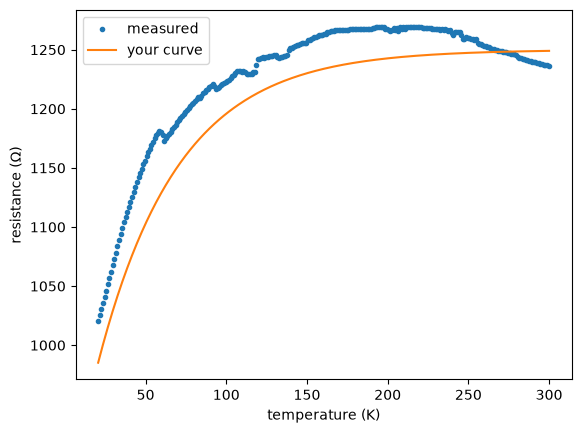

your RMSE = 29.33 ohm


In [8]:
# @title Try to beat curve_fit {run:"auto"}
A_guess = 400 # @param {type:"slider", min:350, max:470, step:5}
k_guess = 0.020 # @param {type:"slider", min:0.015, max:0.035, step:0.001}
R0_guess = 850 # @param {type:"slider", min:800, max:900, step:5}

resistance_guess = saturation_model(temperature, A_guess, k_guess, R0_guess)
fig, ax = plt.subplots()
ax.plot(temperature, resistance, '.', label='measured')
ax.plot(temperature, resistance_guess, '-', label='your curve')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance ($\\Omega$)')
ax.legend()
plt.show()
print(f'your RMSE = {rmse(resistance, resistance_guess):.2f} ohm')

Now let `curve_fit` choose $A$, $k$, and $R_0$. The `p0` list supplies its
starting guesses:

In [9]:
popt_exp, pcov_exp = optimize.curve_fit(
    saturation_model, temperature, resistance, p0=[400, 0.02, 850]
)
resistance_exp = saturation_model(temperature, *popt_exp)
print(f'curve_fit: A = {popt_exp[0]:.1f} ohm, k = {popt_exp[1]:.4f} 1/K, R0 = {popt_exp[2]:.1f} ohm')
print(f'exponential: RMSE = {rmse(resistance, resistance_exp):.2f} ohm')

curve_fit: A = 410.9 ohm, k = 0.0261 1/K, R0 = 849.6 ohm
exponential: RMSE = 9.11 ohm


The three RMSEs are about 37.6, 13.3, and 9.1 $\Omega$ on the *same*
20–300 K readings. The exponential has the lowest score. Before choosing
it, look at the curves and the pattern of their misses:

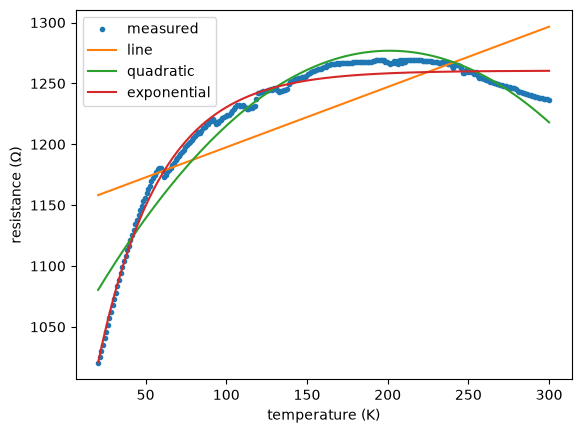

In [10]:
fig, ax = plt.subplots()
ax.plot(temperature, resistance, '.', label='measured')
ax.plot(temperature, resistance_line, '-', label='line')
ax.plot(temperature, resistance_quad, '-', label='quadratic')
ax.plot(temperature, resistance_exp, '-', label='exponential')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance ($\\Omega$)')
ax.legend()

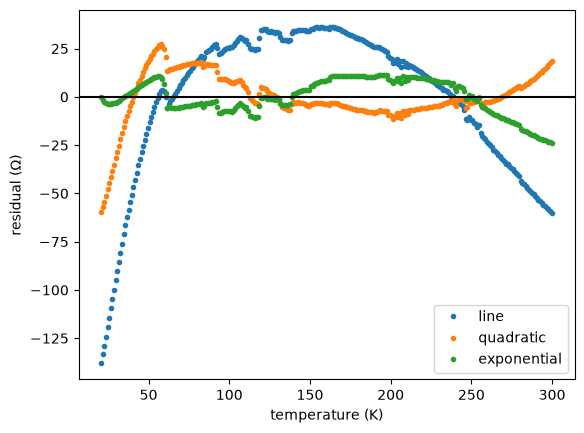

In [11]:
fig, ax = plt.subplots()
ax.plot(temperature, resistance - resistance_line, '.', label='line')
ax.plot(temperature, resistance - resistance_quad, '.', label='quadratic')
ax.plot(temperature, resistance - resistance_exp, '.', label='exponential')
ax.axhline(0, color='black')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('residual ($\\Omega$)')
ax.legend()

The line leaves a broad curved pattern. The two curved forms miss less.
Compare the exponential with the recorded reading near 2 K:

In [12]:
cold = film.iloc[0]
T_cold = cold['temperature_K']
print(f'measured at {T_cold:.1f} K: {cold["resistance_ohm"]:.3f} ohm')
print(f'exponential prediction: {saturation_model(T_cold, *popt_exp):.0f} ohm')

measured at 2.0 K: -0.004 ohm
exponential prediction: 871 ohm


**Conclusion for Example 1:** The exponential gives the lowest RMSE of the
three forms on the 20–300 K readings: about 9.1 $\Omega$. At 2 K it predicts
hundreds of ohms; the measured resistance is near zero.

# Example 2: the transition midpoint

**Question:** At what temperature does film 20198 pass through the middle
of its resistive transition?

Select 2–25 K. Divide resistance by the last reading in that window to
put the curve near zero at its cold end and near one at its warm end.
Call this a *resistance fraction*:

25 transition readings; reference = 1041.2 ohm


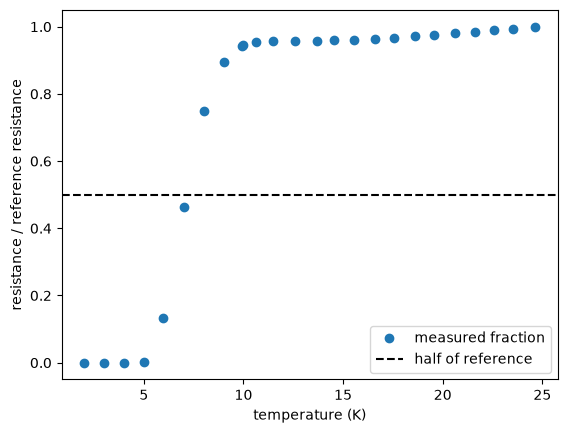

In [13]:
transition = film.loc[(film['temperature_K'] >= 2) & (film['temperature_K'] <= 25)]
transition_T = transition['temperature_K'].to_numpy()
transition_R = transition['resistance_ohm'].to_numpy()
reference_R = transition_R[-1]  # rows run cold to warm; this is near 25 K
fraction = transition_R / reference_R
print(len(transition_T), 'transition readings; reference =', f'{reference_R:.1f} ohm')

fig, ax = plt.subplots()
ax.plot(transition_T, fraction, 'o', label='measured fraction')
ax.axhline(0.5, color='black', linestyle='--', label='half of reference')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance / reference resistance')
ax.legend()

Before fitting, read the one-half crossing from the plot and write down
your estimate. Fit a step-shaped curve to make that estimate reproducible:

$f(T)=1/[1+e^{-(T-T_{\mathrm{mid}})/w}]$.

$T_{\mathrm{mid}}$ is the temperature where this fitted fraction is 0.5;
$w$ controls how quickly it rises, in K. This empirical curve is a compact
description of the measured transition. Its midpoint depends on the
reference reading we chose; it is not a universal critical temperature.

In [14]:
def transition_model(T, T_mid, w):
    """Step-shaped resistance fraction; T_mid and w are in K."""
    return 1 / (1 + np.exp(-(T - T_mid) / w))

Use the Lecture 22 pattern: build predicted fractions, subtract them from
the measured fractions, square the residuals, and return their sum.
Keep the parameter order $T_{\mathrm{mid}}, w$ in the function and in `x0`:

In [15]:
def transition_sse(params):
    T_mid, w = params
    predicted = transition_model(transition_T, T_mid, w)
    residuals = fraction - predicted
    return np.sum(residuals**2)

## Can you beat `minimize`?

Move the sliders to lower SSE (sum of squared residuals). In Colab, run the
cell once to activate the controls. Record your best midpoint, width, and
SSE before running the next cell.

your SSE = 0.6242


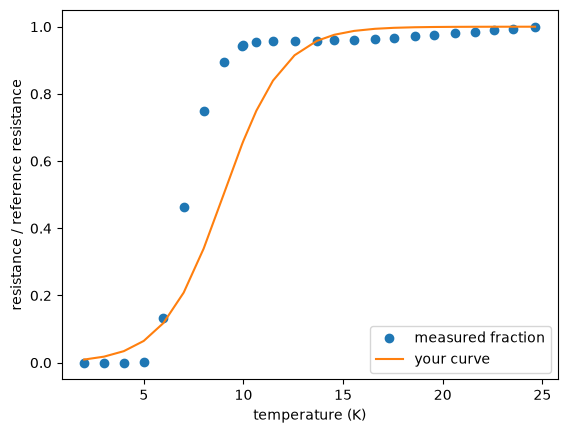

In [16]:
# @title Try to beat minimize {run:"auto"}
T_mid_guess = 9.0 # @param {type:"slider", min:5.0, max:10.0, step:0.1}
w_guess = 1.5 # @param {type:"slider", min:0.3, max:2.5, step:0.1}

guess_fraction = transition_model(transition_T, T_mid_guess, w_guess)
guess_sse = transition_sse([T_mid_guess, w_guess])
fig, ax = plt.subplots()
ax.plot(transition_T, fraction, 'o', label='measured fraction')
ax.plot(transition_T, guess_fraction, '-', label='your curve')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance / reference resistance')
ax.legend()
print(f'your SSE = {guess_sse:.4f}')

Now compare your best score with `minimize` on the same objective:

In [17]:
result_transition = optimize.minimize(transition_sse, x0=[7, 1])
T_mid, w = result_transition.x
print(f'midpoint = {T_mid:.1f} K, width parameter = {w:.1f} K')
print(f'minimize SSE = {result_transition.fun:.4f}')
print('optimizer success:', result_transition.success)

midpoint = 7.2 K, width parameter = 0.7 K
minimize SSE = 0.0206
optimizer success: True


If you tried the sliders, compare your best SSE with the optimizer's score.
How close is the fitted midpoint to your estimate from the first fraction plot?
`success = True` means the optimizer stopped normally. Compare the fitted
curve with the actual points:

RMSE = 0.029 of the reference resistance


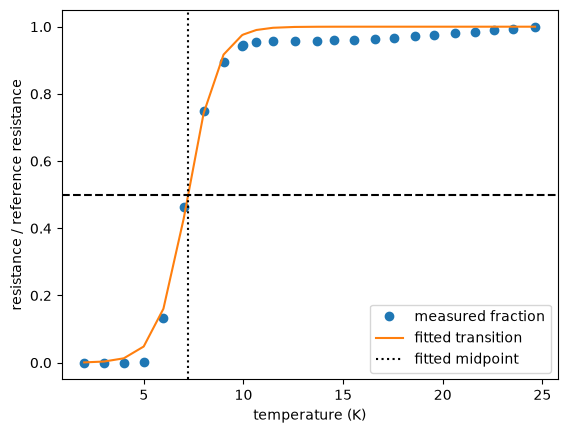

In [18]:
fraction_fit = transition_model(transition_T, T_mid, w)
fig, ax = plt.subplots()
ax.plot(transition_T, fraction, 'o', label='measured fraction')
ax.plot(transition_T, fraction_fit, '-', label='fitted transition')
ax.axhline(0.5, color='black', linestyle='--')
ax.axvline(T_mid, color='black', linestyle=':', label='fitted midpoint')
ax.set_xlabel('temperature (K)')
ax.set_ylabel('resistance / reference resistance')
ax.legend()
print(f'RMSE = {rmse(fraction, fraction_fit):.3f} of the reference resistance')

**Conclusion for Example 2:** With resistance near 25 K as the reference,
film 20198 crosses half of that reference near 7.2 K.

### [Check your understanding]

Apply the Example 2 workflow to **film 20201**. Its transition sits at
higher temperature.

1. Select film 20201 from `data`, then keep 15–40 K readings. Make arrays
   of temperature and resistance. Check for 40 readings.
2. Reassign `transition_T` and `fraction` using this film's last resistance
   in that window as the reference. Plot the fraction with a 0.5 line.
   These notebook names now hold film 20201's arrays; rerun Example 2 from
   its selection cell if you want to restore film 20198's arrays.
3. Reuse `transition_sse` and `transition_model` with a start near `[30, 2]`.
   Check `success`, overlay the fitted curve, and report the midpoint to
   one decimal place. Check for about 29.8 K.
4. Compare the two fitted midpoints in one sentence. What would go wrong
   if you used film 20198's 2–25 K window for this film?

**Optional challenge:** compare the two fitted RMSEs as fractions of their
own reference readings.

# Quiz 7 warm-up

In Q1 you will:
- read `curve_fit` output and explain what a fitted value means,
- distinguish an array attribute from a method call.

In Q2 you will:
- read a `minimize` objective and match entries of `res.x` to what the code computes,
- interpret `res.success`.

## Further reading

* [Penn State 2DCC FeSe transport data package](https://doi.org/10.26207/j3vb-gg87).
* [Berkeley: Least-Squares Regression for Nonlinear Functions](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.05-Least-Square-Regression-for-Nonlinear-Functions.html).